# Câu 5: Thống kê số người đi cùng và khảo sát sự liên quan với khả năng sống sót

Phần 1 – Bài 2 (trang 15–17): Yêu cầu lập trình trên dữ liệu Titanic

In [1]:
SV = "Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT"
DATA = "../../data/"  # thư mục chứa dữ liệu
print(SV)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


In [2]:
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

### Chuẩn bị: thực hiện lại các bước của các câu trước

In [3]:
df = pd.read_csv(DATA + 'titanic.csv', dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

---
## Thực hiện yêu cầu

In [4]:
print(SV)
df['relatives'] = df['sibsp'] + df['parch']
# not_alone = 1 nếu có người thân đi cùng, 0 nếu đi một mình
df['not_alone'] = (df['relatives'] > 0).astype(int)
df['not_alone'].value_counts()

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


not_alone
0    790
1    519
Name: count, dtype: int64

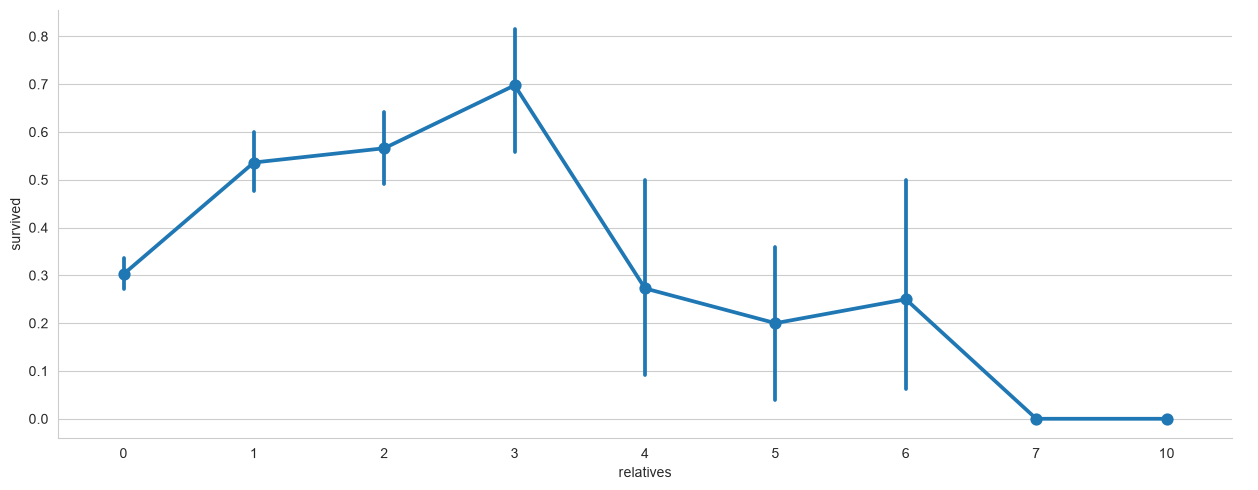

In [5]:
sns.catplot(x='relatives', y='survived', data=df, aspect=2.5, kind='point')
plt.show()

In [7]:
df.groupby('relatives')['survived'].agg(['count', 'mean']).round(2)

,count,mean
relatives,,
0,790,0.30
1,235,0.54
2,159,0.57
3,43,0.70
4,22,0.27
5,25,0.20
6,16,0.25
7,8,0.00
10,11,0.00


In [6]:
df.groupby('not_alone')['survived'].agg(['count', 'mean']).round(3)

,count,mean
not_alone,,
0,790,0.303
1,519,0.503


**Nhận xét:**

- Có 790 người đi một mình và 519 người đi cùng người thân.
- Người đi cùng người thân có tỷ lệ sống sót ≈50,3%, cao hơn hẳn người đi một mình (≈30,3%).
- Tỷ lệ sống sót tăng khi có 1–3 người thân (54% → 70%), nhưng giảm mạnh khi có từ 4 người thân trở lên (≈20–27%), và những người có 7 hoặc 10 người thân đều không sống sót.
- Như vậy gia đình nhỏ có lợi thế, còn gia đình đông (thường là khách hạng 3) khó thoát nạn cùng nhau.
- Lưu ý: trong tài liệu hướng dẫn cột `not_alone` được gán ngược (1 = đi một mình); ở đây `not_alone = 1` nghĩa là *có* người thân đi cùng, đúng với tên gọi.